# Credit Risk Prediction System

An end-to-end machine learning system designed to evaluate borrower default risk and serve real-time predictions in the cloud. In Version 1, the pipeline processes credit data, trains and evaluates predictive models locally, and packages the model artifacts to deploy as a live online prediction endpoint on Google Cloud's Vertex AI.

## 1. Setup

In [25]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

from dotenv import load_dotenv

load_dotenv()

True

### 1.1. Download Dataset
We fetch the credit risk dataset directly from the source to ensure full reproducibility.

In [7]:
os.makedirs("data/raw", exist_ok=True)
!kaggle datasets download -d laotse/credit-risk-dataset -p data/raw --unzip

Dataset URL: https://www.kaggle.com/datasets/laotse/credit-risk-dataset
License(s): CC0-1.0
100%|████████████████████████████████████████| 368k/368k [00:00<00:00, 410kB/s]



### 1.2. Load and Preview the Dataset
Load the unzipped raw credit risk dataset from the local `data/raw/` directory into a Pandas DataFrame and inspect the first few records to verify the schema and feature columns.

In [8]:
# Define the dataset path (update this with your actual file path or URL)
data_path = "data/raw/credit_risk_dataset.csv"

# Load the dataset
df = pd.read_csv(data_path)

# Display the first few rows
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


### 1.3. Initial Dataset Inspection
Check the dataset dimensions, data types, missing values, and target class balance (`loan_status`).

In [9]:
# Check dataset dimensions and column summary
df.info()

# Check missing value counts
print("\nMissing values per column:")
print(df.isnull().sum())

# Check target variable distribution (0 = Non-default, 1 = Default)
print("\nTarget Class Distribution:")
print(df["loan_status"].value_counts(normalize=True))

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB

Missing values per column:
person_age        

In [11]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


### 1.4. Visualizing All Numerical Feature Distributions

To get a complete view of our data before preprocessing, we plot the distributions for all numerical features in the dataset. This helps us inspect skewness, spot extreme outliers across all continuous variables, and evaluate scale differences across features.

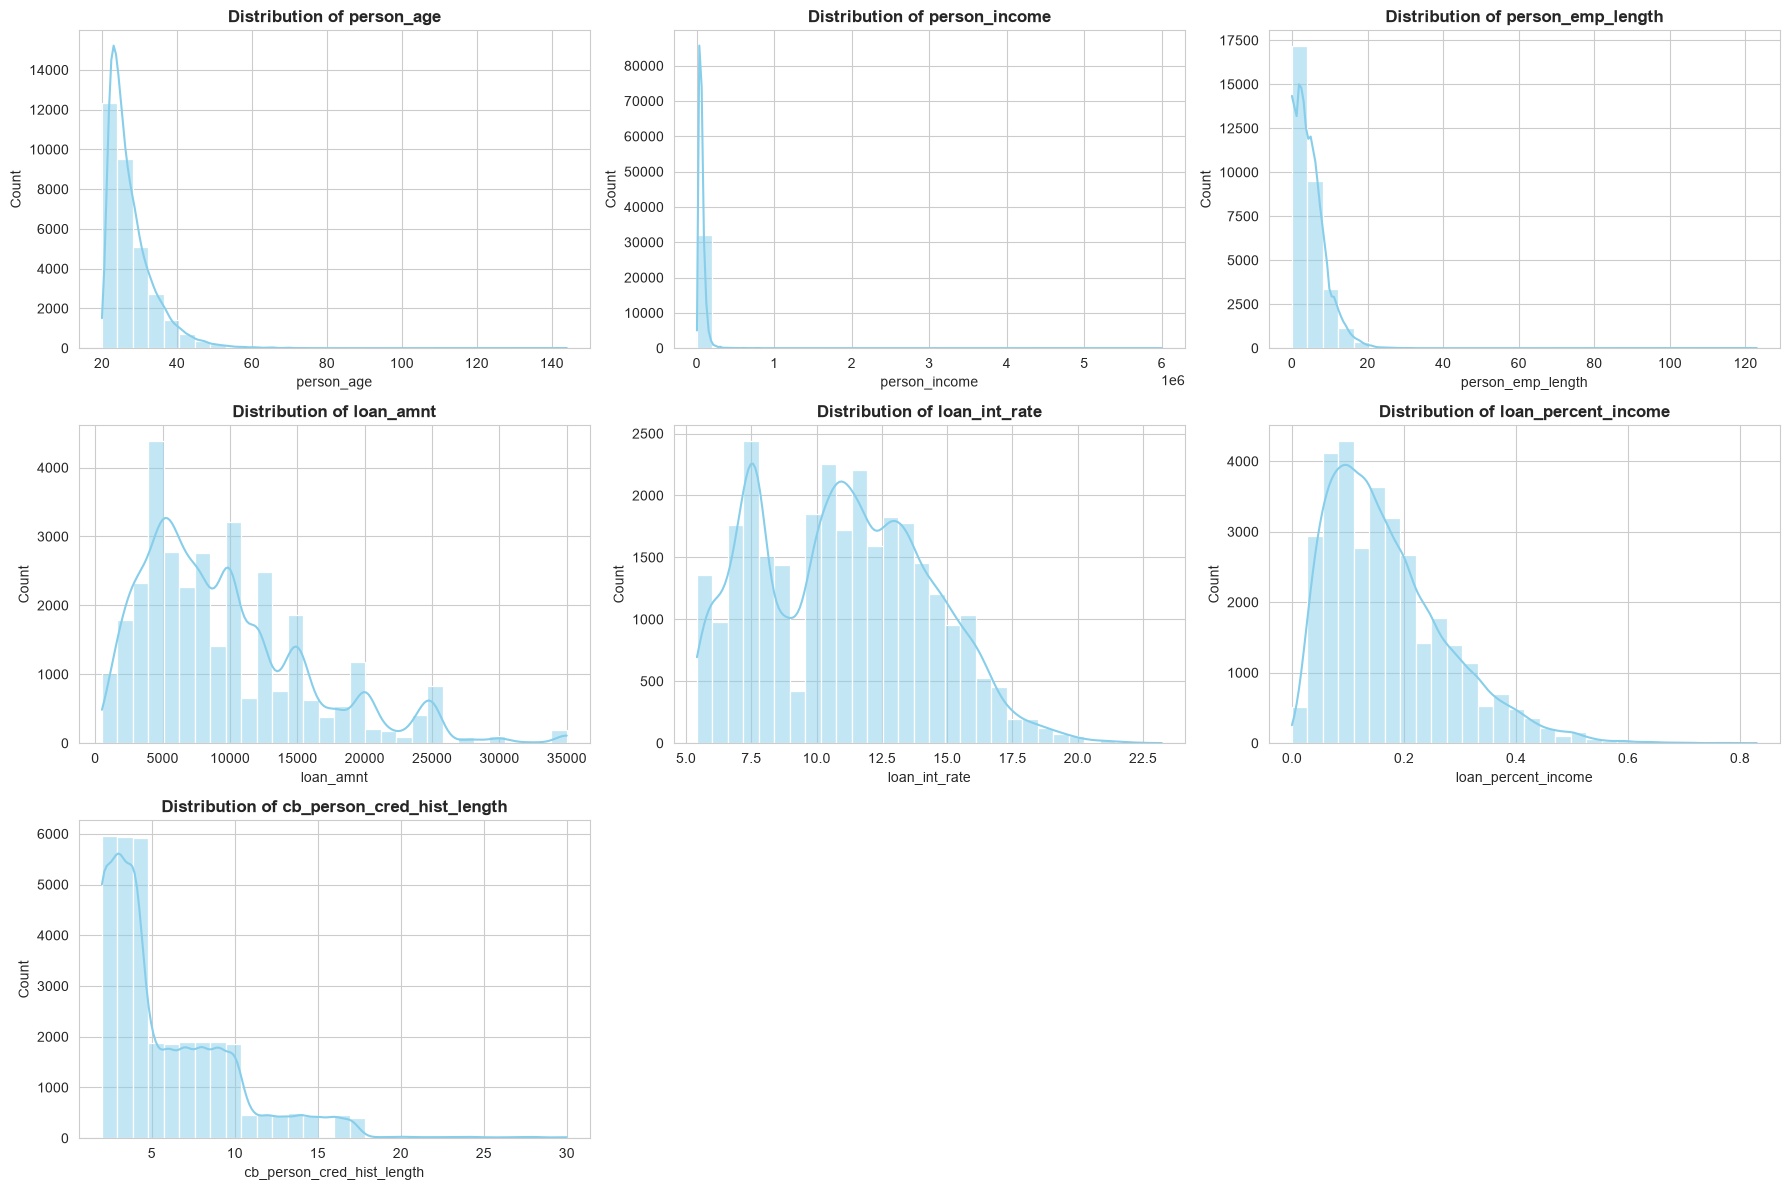

In [18]:
# Set overall plot aesthetics
sns.set_style("whitegrid")

# Select all numerical columns (excluding the target 'loan_status' for feature distribution check)
num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
if "loan_status" in num_cols:
    num_cols.remove("loan_status")

# Set up a 3x3 subplot grid
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 12))
axes = axes.flatten()

# Plot histogram and KDE for each numerical feature
for i, col in enumerate(num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=axes[i], color="skyblue")
    axes[i].set_title(f"Distribution of {col}", fontsize=12, fontweight="bold")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")

# Hide unused subplots in the grid
for j in range(len(num_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Key Insights from Exploratory Data Analysis (EDA)

1. **Outliers & Data Quality Issues:**
   * **`person_age`**: Contains unrealistic values, including an applicant recorded as **144 years old** (with an employment length of **123 years**). These extreme outliers represent data entry errors and need to be filtered out during preprocessing.
   
2. **Missing Values:**
   * **`person_emp_length`**: Missing **895 values** (~2.7% of the dataset).
   * **`loan_int_rate`**: Missing **3,116 values** (~9.6% of the dataset).
   * Both numerical features will require an appropriate imputation strategy (e.g., median imputation) prior to model training.

## 2.Data Cleaning & Preprocessing

In this step, we clean our dataset by addressing the data quality issues identified during EDA:
1. **Remove Outliers:** Filter out extreme anomalies, such as applicants with unrealistic ages ($\ge 100$) or employment lengths ($\ge 60$ years).
2. **Drop Missing Values:** Since missing values account for a small portion of the dataset (~2.7% in `person_emp_length` and ~9.6% in `loan_int_rate`), we drop rows containing null values to ensure a clean baseline dataset without introducing imputed data.

In [19]:
# 1. Filter out extreme age & employment length outliers
df_clean = df[(df["person_age"] < 100) & (df["person_emp_length"] < 60)].copy()

# 2. Drop rows containing missing values
df_clean = df_clean.dropna()

# 3. Verify clean dataset shape and ensure no missing values remain
print(f"Original dataset shape: {df.shape}")
print(f"Cleaned dataset shape:  {df_clean.shape}\n")
print("Remaining missing values per column:")
print(df_clean.isnull().sum())

Original dataset shape: (32581, 12)
Cleaned dataset shape:  (28632, 12)

Remaining missing values per column:
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64


## 3. Feature Engineering & Pipeline Construction

To prepare the dataset for model training without data leakage, we build a Scikit-Learn preprocessing pipeline:
* **Categorical Features:** Transformed using `OneHotEncoder(handle_unknown='ignore')`.
* **Numerical Features:** Scaled using `StandardScaler()`.
* **Estimator:** Bundled together with a baseline classifier inside a single `Pipeline` object to streamline training and future cloud inference.

In [21]:
# 1. Separate features and target
X = df_clean.drop(columns=["loan_status"])
y = df_clean["loan_status"]

# 2. Train-test split (using stratification to maintain target ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Identify categorical and numerical column names
cat_cols = X.select_dtypes(include=["object", "category", "str"]).columns.tolist()
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

# 4. Define ColumnTransformer for preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ]
)

# 5. Create the complete baseline pipeline
model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(random_state=42, max_iter=1000)),
    ]
)

# 6. Fit the model on training data
model_pipeline.fit(X_train, y_train)
print("Pipeline trained successfully!")

Pipeline trained successfully!


## 4. Model Evaluation

Now we evaluate our trained baseline model on the holdout test set. We will look at:
* **Classification Report:** To check Precision, Recall, and F1-score for both classes. (In credit risk, high Recall for the 'Default' class is crucial).
* **ROC-AUC Score:** To measure the model's ability to distinguish between defaults and non-defaults.
* **Confusion Matrix:** To visually inspect true positives vs. false negatives.

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.89      0.95      0.92      4486
           1       0.75      0.56      0.64      1241

    accuracy                           0.86      5727
   macro avg       0.82      0.75      0.78      5727
weighted avg       0.86      0.86      0.86      5727

ROC-AUC Score: 0.8713



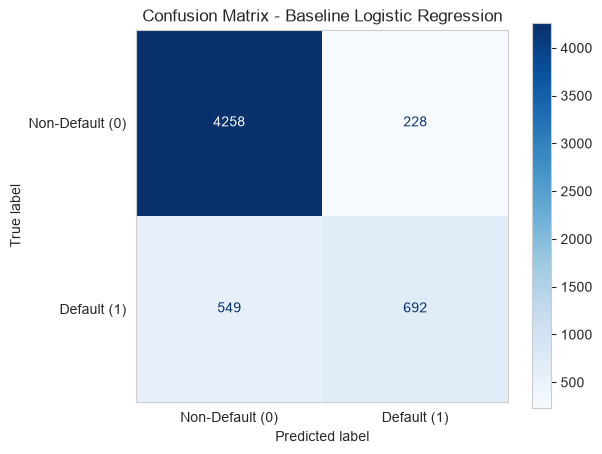

In [23]:
# 1. Generate predictions and probabilities for the test set
y_pred = model_pipeline.predict(X_test)
y_pred_proba = model_pipeline.predict_proba(X_test)[:, 1]

# 2. Print evaluation metrics
print("=== Classification Report ===")
print(classification_report(y_test, y_pred))

roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}\n")

# 3. Plot the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Non-Default (0)", "Default (1)"])

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", ax=ax)
plt.title("Confusion Matrix - Baseline Logistic Regression")
plt.grid(False) # Turn off gridlines for a cleaner matrix
plt.show()

### Model Performance Note

Since the primary goal of Version 1 is to establish the end-to-end ML engineering pipeline (local training $\rightarrow$ Vertex AI deployment) rather than optimizing model accuracy, we will accept these baseline metrics. The current model successfully demonstrates the workflow, and future iterations (V2/V3) can focus on improving default detection (Recall) using more complex architectures like XGBoost and hyperparameter tuning.

Next, we will serialize and save our trained pipeline so it can be uploaded to the cloud.

In [24]:
import joblib
import os

# Create a directory to store the local model artifact
os.makedirs("models", exist_ok=True)

# Save the complete pipeline (preprocessing + classifier)
artifact_path = "models/model.joblib"
joblib.dump(model_pipeline, artifact_path)

print(f"Model artifact successfully saved to: {artifact_path}")

Model artifact successfully saved to: models/model.joblib


## 5. Model Deployment to Google Cloud Vertex AI

In this final step, we move our local model artifact into production on Google Cloud:
1. Initialize the Google Cloud Storage (GCS) bucket and upload `model.joblib`.
2. Register the uploaded artifact in the Vertex AI Model Registry using a pre-built Scikit-Learn container.
3. Deploy the registered model to a live Vertex AI Endpoint for real-time online predictions.

In [32]:
import os
from google.cloud import storage
from google.cloud import aiplatform

# Load configuration from environment variables
PROJECT_ID = os.getenv("GCP_PROJECT_ID")
REGION = os.getenv("GCP_REGION", "us-central1")

BUCKET_NAME = f"{PROJECT_ID}-credit-risk-models"
LOCAL_MODEL_PATH = "models/model.joblib"
GCS_MODEL_DIR = f"gs://{BUCKET_NAME}/v1/"

# 1. Upload model artifact to Google Cloud Storage
storage_client = storage.Client(project=PROJECT_ID)
bucket = storage_client.bucket(BUCKET_NAME)

if not bucket.exists():
    bucket = storage_client.create_bucket(bucket, location=REGION)

blob = bucket.blob("v1/model.joblib")
blob.upload_from_filename(LOCAL_MODEL_PATH)
print(f"Model successfully uploaded to: {GCS_MODEL_DIR}model.joblib")

# 2. Initialize Vertex AI
aiplatform.init(project=PROJECT_ID, location=REGION)

# 3. Register model in Vertex AI Model Registry
model = aiplatform.Model.upload(
    display_name="credit-risk-model-v1",
    artifact_uri=GCS_MODEL_DIR,
    serving_container_image_uri="us-docker.pkg.dev/vertex-ai/prediction/sklearn-cpu.1-3:latest",
)
print(f"Model registered in Vertex AI: {model.resource_name}")

# 4. Create Endpoint and Deploy (Note: Deployment takes roughly 10-15 minutes)
endpoint = model.deploy(
    endpoint_display_name="credit-risk-endpoint",
    machine_type="n1-standard-4",
    min_replica_count=1,
    max_replica_count=1,
    sync=True
)

print(f"Deployment complete! Endpoint resource name: {endpoint.resource_name}")

## 6. Live Online Inference & Testing
With the model deployed to a live Vertex AI Endpoint, we evaluate real-time predictions by passing unseen borrower profiles. We test inference using the Vertex AI Python SDK directly within our environment, as well as via REST API requests.

### 6.1. Real-Time Online Prediction via Vertex AI SDK
We retrieve our deployed endpoint reference and submit sample feature payloads matching the schema expected by our Scikit-Learn preprocessing pipeline.

In [ ]:
import os
from google.cloud import aiplatform

# 1. Load project configurations
PROJECT_ID = os.getenv("GCP_PROJECT_ID")
REGION = os.getenv("GCP_REGION", "us-central1")

# Initialize Vertex AI SDK
aiplatform.init(project=PROJECT_ID, location=REGION)

# 2. Get the deployed endpoint reference
# Option A: If you have the endpoint resource name from your deployment output:
# endpoint = aiplatform.Endpoint("projects/PROJECT_NUMBER/locations/us-central1/endpoints/ENDPOINT_ID")

# Option B: Look up the endpoint by display name
endpoints = aiplatform.Endpoint.list(
    filter='display_name="credit-risk-endpoint"'
)
endpoint = endpoints[0]

# 3. Define sample payload matching your original dataframe schema
sample_instances = [
    {
        "person_age": 25,
        "person_income": 50000,
        "person_home_ownership": "RENT",
        "person_emp_length": 3.0,
        "loan_intent": "PERSONAL",
        "loan_grade": "B",
        "loan_amnt": 10000,
        "loan_int_rate": 11.5,
        "loan_percent_income": 0.20,
        "cb_person_default_on_file": "N",
        "cb_person_cred_hist_length": 4,
    },
    {
        "person_age": 45,
        "person_income": 120000,
        "person_home_ownership": "MORTGAGE",
        "person_emp_length": 15.0,
        "loan_intent": "VENTURE",
        "loan_grade": "A",
        "loan_amnt": 5000,
        "loan_int_rate": 7.2,
        "loan_percent_income": 0.04,
        "cb_person_default_on_file": "N",
        "cb_person_cred_hist_length": 10,
    },
]

# 4. Make live online prediction request
response = endpoint.predict(instances=sample_instances)

# 5. Print out the prediction results
print("Raw Endpoint Response:")
print(response.predictions)

# Interpret results (0 = Non-Default, 1 = Default)
for i, pred in enumerate(response.predictions):
    # Depending on container output, Scikit-learn endpoints return either 
    # class labels [0, 1] or probabilities [[p0, p1]]
    print(f"Sample {i+1} Prediction: {pred}")

In [ ]:
# ENDPOINT_ID="YOUR_ENDPOINT_ID"
# PROJECT_ID="YOUR_PROJECT_ID"
# REGION="us-central1"

# curl -X POST \
#   -H "Authorization: Bearer $(gcloud auth print-access-token)" \
#   -H "Content-Type: application/json; charset=utf-8" \
#   -d @input.json \
#   "https://${REGION}-aiplatform.googleapis.com/v1/projects/${PROJECT_ID}/locations/${REGION}/endpoints/${ENDPOINT_ID}:predict"

## 7. Resource Cleanup & Decommissioning
To prevent ongoing charges and avoid consuming Google Cloud credits, we undeploy the model from the active Vertex AI Endpoint and delete all associated cloud resources (Endpoint, Model Registry entry, and GCS storage bucket).

### 7.1. Undeploy Model and Delete Vertex AI Endpoint
Online prediction endpoints incur charges while active. We first undeploy the model from the endpoint and then delete the endpoint resource.

In [ ]:
import os
from google.cloud import aiplatform, storage

# 1. Load project configurations
PROJECT_ID = os.getenv("GCP_PROJECT_ID")
REGION = os.getenv("GCP_REGION", "us-central1")
BUCKET_NAME = f"{PROJECT_ID}-credit-risk-models"

aiplatform.init(project=PROJECT_ID, location=REGION)

# 2. Undeploy models and delete Endpoints
endpoints = aiplatform.Endpoint.list(
    filter='display_name="credit-risk-endpoint"'
)
for ep in endpoints:
    print(f"Undeploying models and deleting Endpoint: {ep.resource_name}")
    ep.undeploy_all()
    ep.delete()

# 3. Delete registered Model artifacts from Vertex AI Model Registry
models = aiplatform.Model.list(filter='display_name="credit-risk-model-v1"')
for m in models:
    print(f"Deleting Model from Registry: {m.resource_name}")
    m.delete()

# 4. Clean up GCS Storage Bucket
storage_client = storage.Client(project=PROJECT_ID)
try:
    bucket = storage_client.get_bucket(BUCKET_NAME)
    bucket.delete(force=True)  # Forces deletion of all blobs inside the bucket
    print(f"GCS Bucket '{BUCKET_NAME}' successfully deleted.")
except Exception as e:
    print(f"GCS Bucket cleanup notice: {e}")

print("All cloud resources successfully cleaned up!")